In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pd.set_option('display.max_columns', None)

### 0.1. Load data and create a copy of it to ensure we retain an unaltered version of the data

In [3]:
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
# copy data to keep an unaltered version
df = data.copy()

### 0.2. Get some basic information of the data set

In [5]:
df.shape

(2443651, 9)

In [6]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [8]:
round(df.describe(), 2)

,uid,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00,2443651.00
mean,1370545.35,2.15,480.63,89.24,25.90
std,816056.17,2.19,5944.12,345.61,240.48
min,1.00,0.00,0.00,0.00,0.00
25%,658921.50,0.00,0.00,9.99,0.00
50%,1349029.00,0.00,0.00,19.09,0.00
75%,2060685.50,4.40,59.00,45.99,0.00
max,2828593.00,5.00,1356658.00,100000.00,50000.00


## Part 1: Understanding Product Categories
**Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?**

### 1.1 Generating a frequency table for product category

In [9]:
cat_freq = df["category"].value_counts()
cat_freq_norm = df["category"].value_counts(normalize=True).round(2)

freq_table = pd.concat([cat_freq, cat_freq_norm], axis=1)
freq_table.columns = ['absolute_frequency', 'relative_frequency']

display(freq_table)

,absolute_frequency,relative_frequency
category,,
Sports & Outdoors,836265,0.34
Beauty,19312,0.01
"Handmade Clothing, Shoes & Accessories",19229,0.01
Bath & Body,19092,0.01
Birthday Gifts,18978,0.01
...,...,...
Alexa Built-In Devices,107,0.00
Motorbike Chassis,107,0.00
Plugs,107,0.00


The top 5 product categories are:
- Sports & Outdoors
- Beauty
- Handmade Clothing, Shoes & Accessories
- Bath & Body
- Birthday Gifts

The Sports & Outdoors category dominates the frequencies by a large margin, being over 40 times bigger than the following category.

### 1.2 Visualising the frequencies

<function matplotlib.pyplot.show(close=None, block=None)>

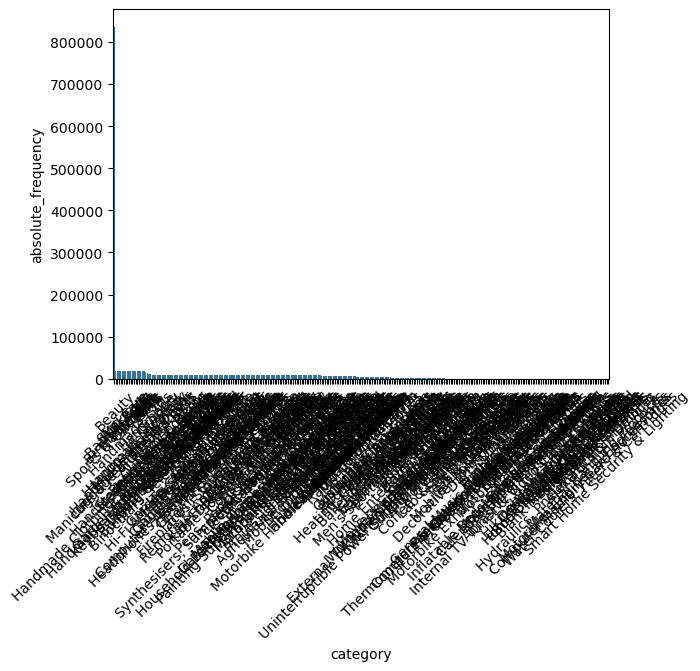

In [10]:
sns.barplot(x="category", y="absolute_frequency", data=freq_table)
plt.xticks(rotation=45)  
plt.show

The barplot does not appear to be great at visualising the whole set of categories, so let's see just the top 5.

<function matplotlib.pyplot.show(close=None, block=None)>

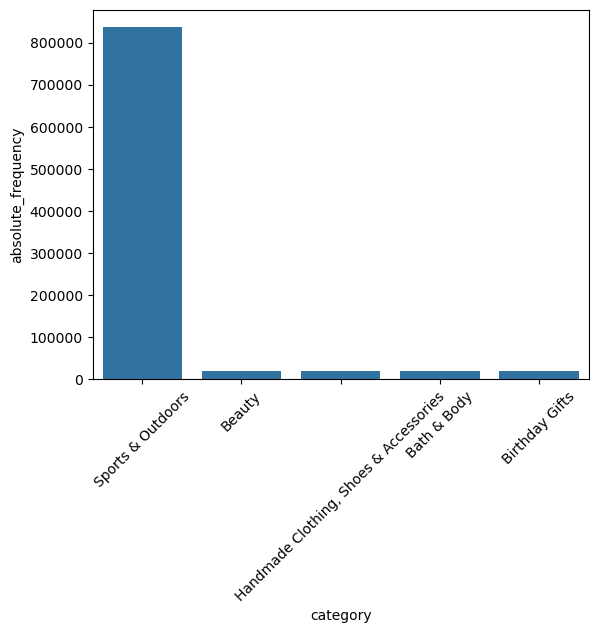

In [11]:
# get the top5 as a subset:
top5_cat = freq_table.iloc[0:5]

sns.barplot(x="category", y="absolute_frequency", data=top5_cat)
plt.xticks(rotation=45)  
plt.show

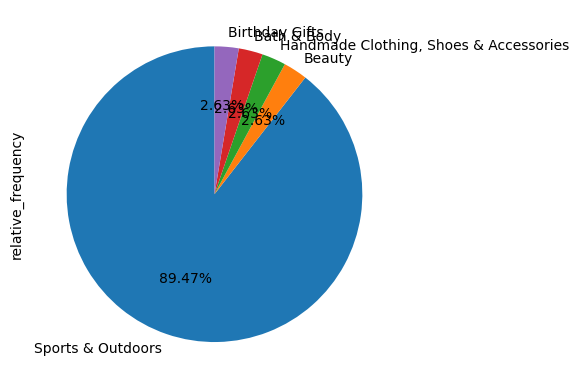

In [12]:
top5_cat.plot.pie(y="relative_frequency", startangle=90,autopct='%1.2f%%', legend=False)
plt.show()

As was suggested by the frequency tables, both the barplot the pie chart also show that the Sports & Outdoors category dominates the listing frequency by a very wide margin.

## Part 2: Delving into Product Pricing
**Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?**

### 2.1 Centrality

In [13]:
price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()

print(f"Price mean: {price_mean}")
print(f"Price median: {price_median}")
print(f"Price mode: {price_mode}")

Price mean: 89.24380943923663
Price median: 19.09
Price mode: 0    9.99
Name: price, dtype: float64


The average (mean) price point of products listed is GBP89.24, which is significantly higher than the mode of GBP9.99. This suggests that while there are expensive items available that skew the mean to be fairly high, there are many more items on sale for cheap prices below 10 pounds.

### 2.2 Dispersion

In [14]:
df["price"].describe()


count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [15]:
price_var = df["price"].var()
price_std = df["price"].std()

price_min = df["price"].min()
price_max = df["price"].max()

price_q1 = df["price"].quantile(.25)
price_q3 = df["price"].quantile(.75)

print(f"The variance in prices is {round(price_var, 2)} and the standard deviation is {round(price_std, 2)}")
print(f"The prices range from {round(price_min, 2)} to {round(price_max,2)}, prices recorded in GBP.")
print(f"The interquantile range is between {round(price_q1, 2)} and {round(price_q3, 2)}.")

The variance in prices is 119445.49 and the standard deviation is 345.61
The prices range from 0.0 to 100000.0, prices recorded in GBP.
The interquantile range is between 9.99 and 45.99.


The recorded prices have an extremely wide range, with the minimum at GBP0 and the maximum at GBP100,000.
This is also reflected in the dispersion statistics: the standard deviation is approximately GBP345.61, indicating that the prices significantly vary from the average price of GBP89.24.

The interquantile range also shows that 50% of products listed have prices between GBP9.99 and GBP45.99, significantly below average, but starting at the mode price of the dataset.

### 2.3 Visualisation

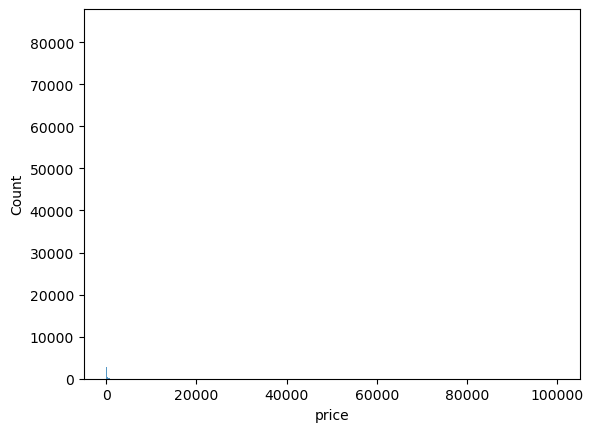

In [22]:
sns.histplot(df["price"], bins="auto")
plt.show()

Because the range of the item prices is so wide, with most items concentrated in one part, the histogram does not visualise the information reasonably. Even with a defined amount of bins, the only information that can be derived from it is that the vast majority of products is priced in the very low price range.

This data could be better visualised in a histogram when the outliers are removed from the dataset, making the price range smaller and more reasonable. Another option could be to look at the different quantiles separately, as most of the expensive outliers would be in the Q4 bucket, though its range would be almost as vast as the whole dataset.

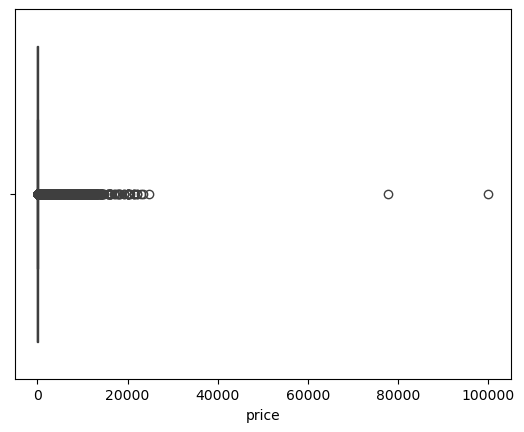

In [17]:
sns.boxplot(data=df, x="price")
plt.show()

The boxplot shows a signinficant amount of outliers that fall outside of the range the it calculates, most or all at the upper end, supporting the data and visualisation seen before. In particular, there are two outliers at approximately GBP75,000 and GBP100,000 that alone skew the data to higher prices. Other outliers end at approximately GBP25,000.

Due to the outliers, the spread is not well readable from the boxplot.

## 3. Unpacking the Product Ratings

**Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?**

### 3.1 Centrality

In [18]:
rating_mean = df["stars"].mean()
rating_median = df["stars"].median()
rating_mode = df["stars"].mode()

print(f"The mean rating is {round(rating_mean,2)}, the median {rating_median} and the mode {rating_mode}.")


The mean rating is 2.15, the median 0.0 and the mode 0    0.0
Name: stars, dtype: float64.


According to the dataset descriptions, the star rating of 0 means that no ratings were found. The median, middle value, being 0, means that at least 50% of items listed have no reviews. This suggests a trend of buyers not leaving ratings. Alternatively, many items have never been purchased.

The mean star rating of items skews towards the lower end, as it is being significantly affected by the many items without reviews having a 0 in this column.

### 3.2 Dispersion

In [19]:
rating_var = df["stars"].var()
rating_std = df["stars"].std()

rating_min = df["stars"].min()
rating_max = df["stars"].max()

rating_q1 = df["stars"].quantile(.25)
rating_q3 = df["stars"].quantile(.75)

print(f"The variance in star ratings is {round(rating_var, 2)} and the standard deviation is {round(rating_std, 2)}")
print(f"The ratings range from {round(rating_min, 2)} to {round(rating_max,2)}, prices recorded in GBP.")
print(f"The interquantile range is between {round(rating_q1, 2)} and {round(rating_q3, 2)}.")

The variance in star ratings is 4.82 and the standard deviation is 2.19
The ratings range from 0.0 to 5.0, prices recorded in GBP.
The interquantile range is between 0.0 and 4.4.


A standard deviation of 2.19 in data that ranges from 0-5 is significant and suggests that many items have a star rating deviating from the mean rating of 2.19. The interquantile range being between 0 and 4.4 stars tells us that not only 50% of products fall into that range, but also the bottom quartile exists in that range as 0 is the minimum value available in the data. On the other hand, this also suggests that 25% of items have a rating higher than 4.4.

### 3.3 Shape of distribution

In [20]:
round(float(df["stars"].skew()), 2)

0.08

In [21]:
round(float(df["stars"].kurt()), 2)

-1.93

The star ratings have a skewness of 0.08 which suggests a fairly symmetrical distribution.
The kurtosis at -1.93 suggests a light-tailed distribution.

### 3.4 Visualisation

<Axes: xlabel='stars', ylabel='Count'>

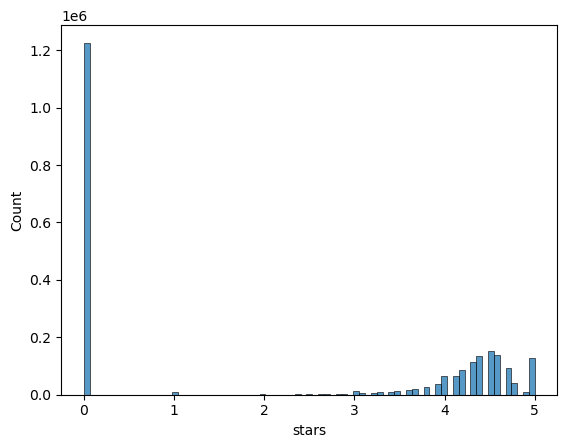

In [23]:
sns.histplot(df["stars"], bins="auto")

The histogram visualisation shows a massive spike at 0 and a separate bundle of values concentrated between 4 and 5 stars, as was suggested by the interquantile range as well. As we know that the rating of 0 means the item has no recorded ratings, based on this graph we can say that the most common ratings are 4 and 5

The histogram is visually at odds with the calculation of skewness and kurtosis done above. In this case the huge spike of 0s counteracts the rest of the data as more than 50% of the data falls there, making the mathematical calculations unreliable to analyse the rest of the data in this dataset. In the histogram we can clearly see that the distribution is not symmetrical as the skewness of 0.08 suggests, but rather the values are split in a distribution near 4 and 5 stars and the spike at 0. Visually the data also suggests high kurtosis, a heavy tail on the right, but the amount of data centred at 0 reduces the mathematical significance of the data on the right making the kurtosis value negative which normally suggests very flat and light tailed data.